# doomscroll — an end-to-end feed ranking demo

**Question.** Given a stream of (user, video) impressions, can a small neural ranker plus a
taste-conditioned *composer* order a session to maximise a graded engagement score (IWE), and does
it beat popularity / affinity / oracle-free baselines?

**Target.** Per-user graded NDCG@10 over 5 action heads (tier gains `[0,1,2,3,4]`), plus IWE in a
closed-loop simulator.

**How to read this notebook.**

| Section | Uses | Nature |
|---|---|---|
| Data loading, EDA, task, features | real `features_*.parquet` logs | **real data** |
| Improved network, training loop, evaluation | trained checkpoints + committed results | **real numbers** |
| Live single-subject simulation | the closed-loop simulator | **simulated** (no causal claims) |

Seed 42 throughout. CPU only.

## 0. Setup — environment, dataset fingerprint, reproducibility

In [1]:
import json, platform, subprocess, sys
from pathlib import Path

import numpy as np
import torch

REPO = Path.cwd()
if not (REPO / "recommender-engine").exists():          # tolerate being run from inside the engine
    REPO = REPO.parent
ENGINE = REPO / "recommender-engine"
sys.path.insert(0, str(ENGINE))
torch.set_num_threads(8)

try:
    commit = subprocess.check_output(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                                     text=True).strip()
except Exception:
    commit = "(no git)"

fp = json.loads((REPO / "notes" / "results" / "fingerprint.json").read_text())
print("doomscroll end-to-end demo")
print(f"python {platform.python_version()} | torch {torch.__version__} | device=cpu | seed=42 | git {commit}")
print("DISCLAIMER: offline metrics come from real logs; the live-simulation section is SIMULATED.")
print("\ndataset fingerprint (sha256 per split):")
for s in ("train", "val", "test"):
    m = fp["splits"][s]
    print(f"  {s:<5} rows={m['n_rows']:>9,}  users={m['n_users']:>7,}  items={m['n_items']:>7,}"
          f"  {m['sha256'][:12]}…")

doomscroll end-to-end demo
python 3.13.14 | torch 2.13.0+cu130 | device=cpu | seed=42 | git 0ea1475
DISCLAIMER: offline metrics come from real logs; the live-simulation section is SIMULATED.

dataset fingerprint (sha256 per split):
  train rows=2,612,256  users= 13,269  items=568,189  93f9ca782e12…
  val   rows=1,959,189  users= 11,218  items=487,026  2d1345b743c9…
  test  rows=1,959,194  users= 10,634  items=444,869  897b6a5798c9…


## 1. Data loading

Real feature artifacts live in `recommender-engine/artifacts/features_{split}.parquet`. We always
read a **column subset** (never the full frame), and the split boundaries are time-based cuts so
val/test are strictly future data.

In [2]:
import pandas as pd
from feed.data import load_split, DENSE

sub = ["user_id", "item_id", "ts", "tier", "is_search", "cold_item", "i_mean_score", "uc_lift"]
frames = {}
for s in ("train", "val", "test"):
    df = load_split(s, columns=sub)
    frames[s] = df
    print(f"{s:<5} rows={len(df):>9,}  cols={df.shape[1]}  users={df['user_id'].nunique():>7,}"
          f"  search={df['is_search'].mean():.3f}  cold_item={df['cold_item'].mean():.3f}")
print("\nhead of train:")
frames["train"].head(5)

train rows=2,612,256  cols=8  users= 13,269  search=0.112  cold_item=0.068
val   rows=1,959,189  cols=8  users= 11,218  search=0.122  cold_item=0.062
test  rows=1,959,194  cols=8  users= 10,634  search=0.075  cold_item=0.054

head of train:


,user_id,item_id,ts,tier,is_search,cold_item,i_mean_score,uc_lift
0,1059,2408801,1685704949806,0,1,0,1.500000,1.376457
1,1059,650060,1685704949806,0,1,0,0.000000,1.311098
2,1059,3078261,1685704949806,0,1,0,0.000000,1.252619
3,1059,2776220,1685704949806,2,1,0,0.923077,1.199988
4,1059,1262505,1685715750958,0,1,0,0.750000,0.000000


## 2. EDA — figures and result tables (rendered, not re-plotted)

### `notes/figures/01_ladder.png`

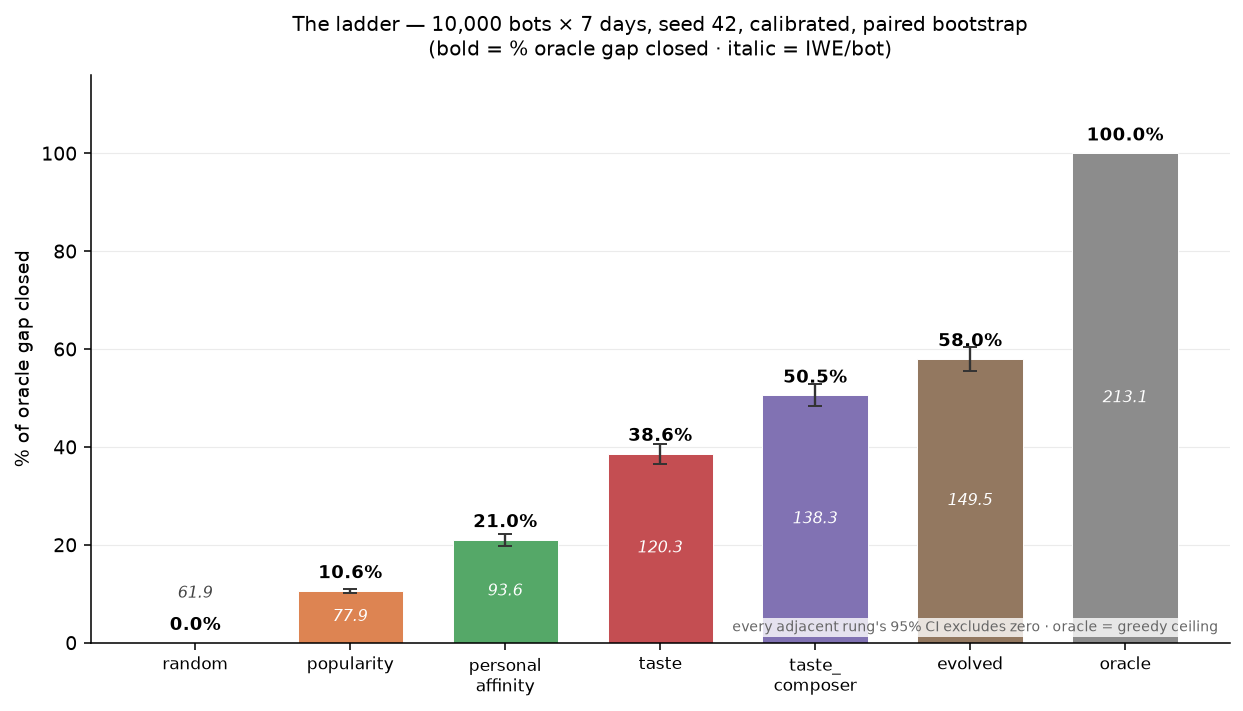

### `notes/figures/02_generations.png`

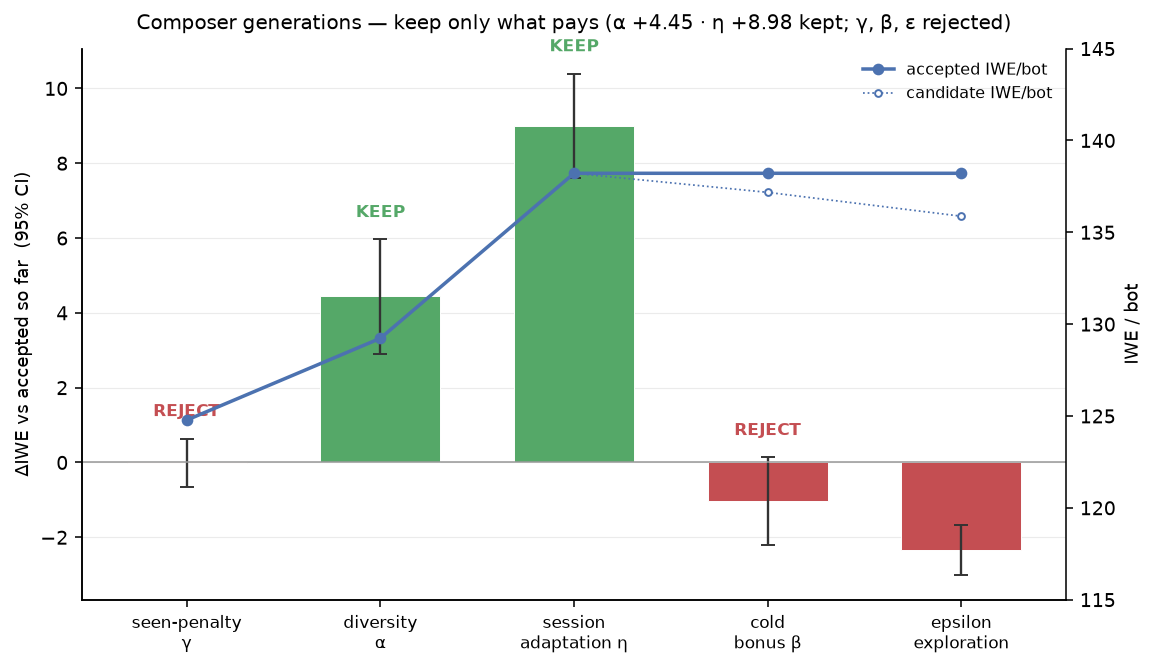

### `notes/figures/03_calibration.png`

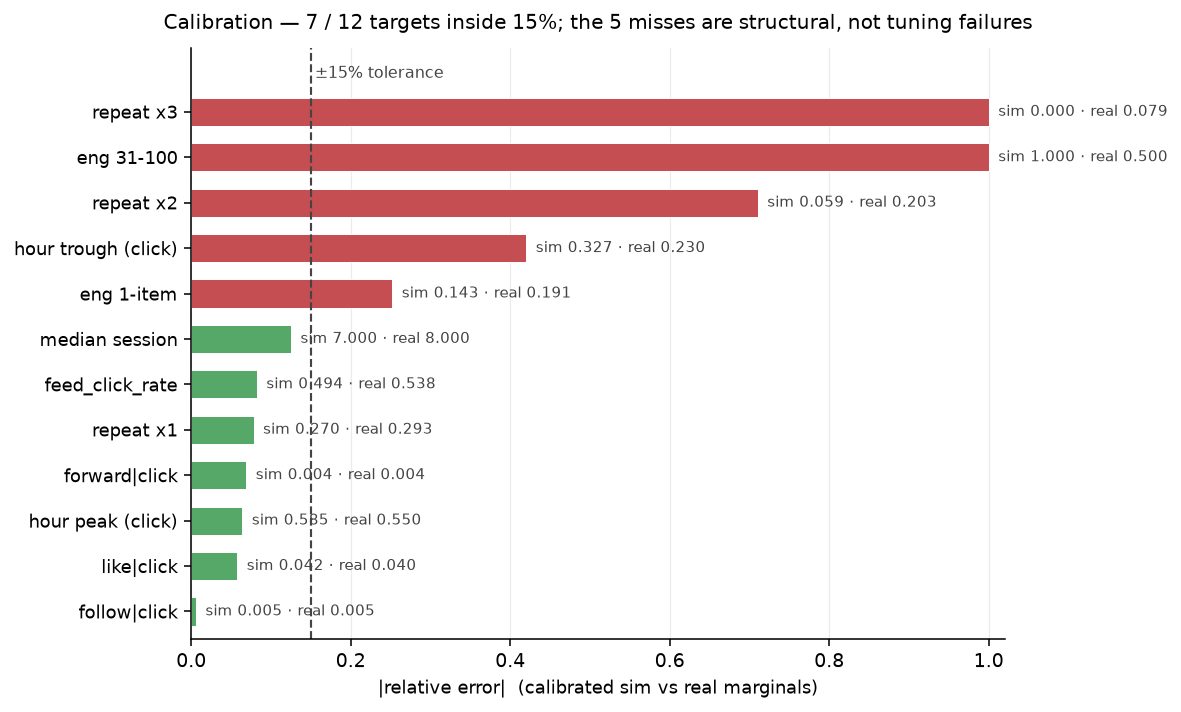

### `notes/figures/04_cohorts.png`

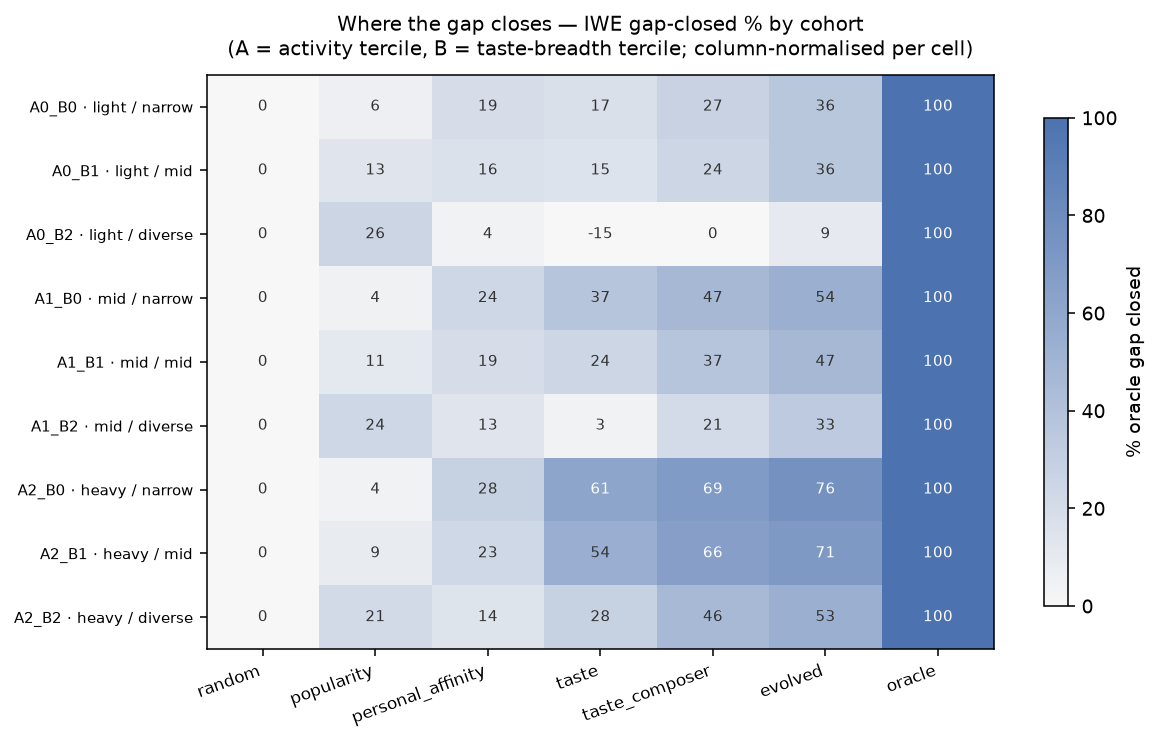

### `notes/figures/05_retention.png`

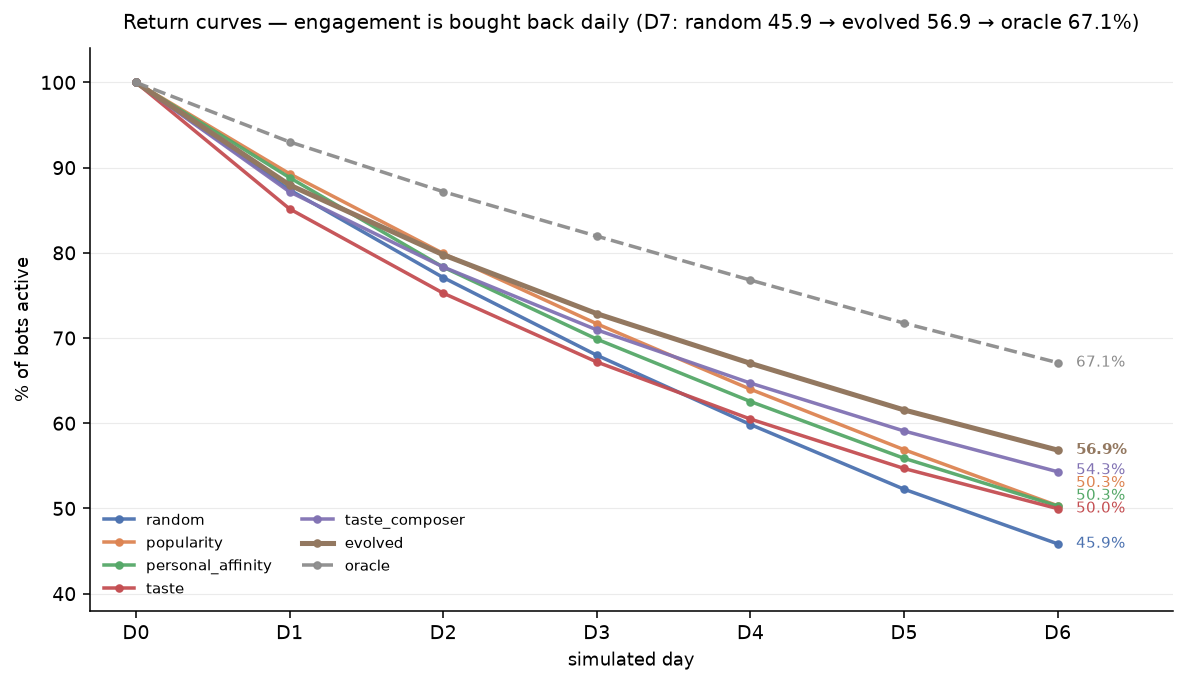

### `notes/figures/06_loss_diagnostics.png`

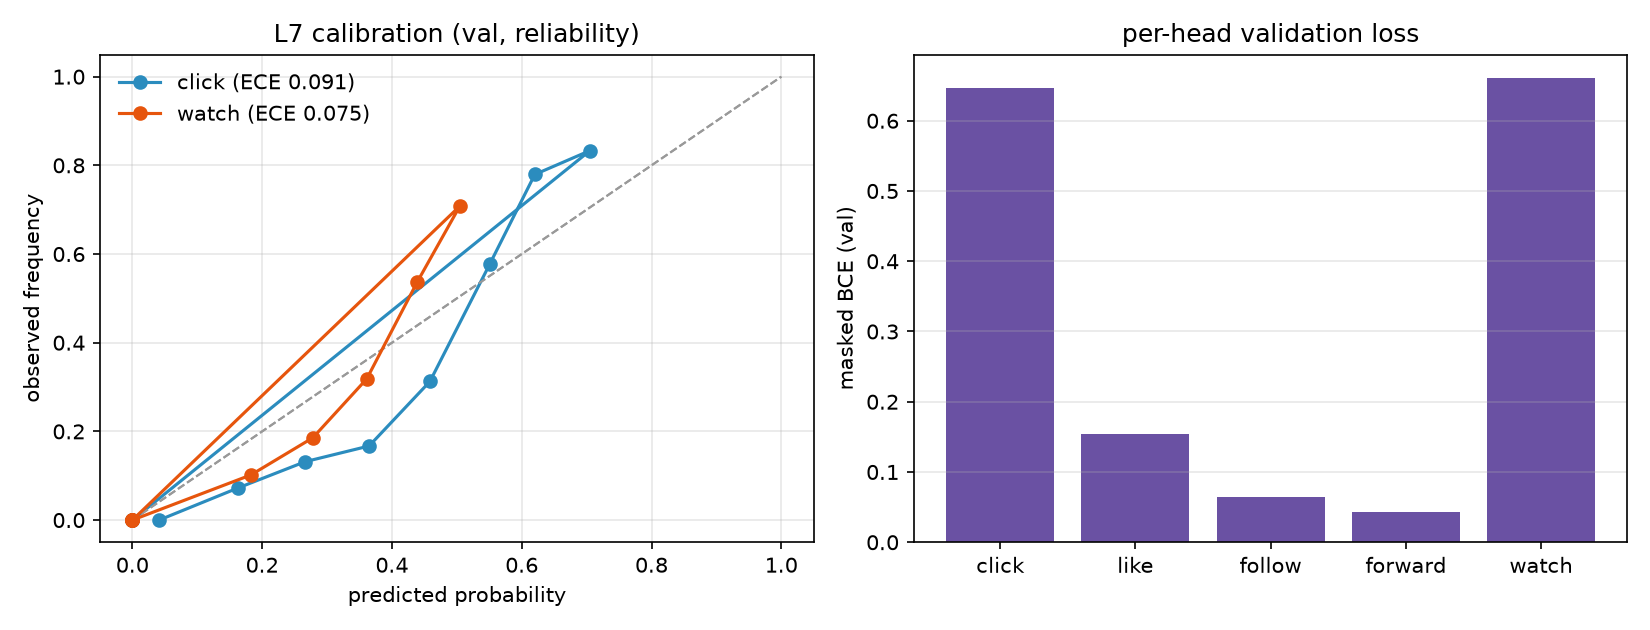

In [3]:
from IPython.display import Image, Markdown, display

for p in sorted((REPO / "notes" / "figures").glob("*.png")):
    display(Markdown(f"### `notes/figures/{p.name}`"))
    display(Image(filename=str(p)))

In [4]:
for name in ("capacity.json", "loss_ablation.json", "improve.json",
             "loss_diagnostics.json", "fingerprint.json"):
    p = REPO / "notes" / "results" / name
    display(Markdown(f"### `notes/results/{name}`"))
    txt = json.dumps(json.loads(p.read_text()), indent=1)
    print(txt[:1800] + ("\n… (truncated)" if len(txt) > 1800 else ""))

### `notes/results/capacity.json`

{
 "phase": 7,
 "fast": false,
 "seed": 42,
 "max_rows": null,
 "primary_k": 10,
 "val_feed": {
  "baseline": {
   "ndcg@10": {
    "mean": 0.49608810135523446,
    "lo": 0.49080706613430314,
    "hi": 0.5016075836384527,
    "n_users": 8376,
    "n_boot": 2000
   },
   "ndcg@20": {
    "mean": 0.5496959239893471,
    "lo": 0.5447592696337592,
    "hi": 0.5548653780176186,
    "n_users": 8376,
    "n_boot": 2000
   }
  },
  "wide": {
   "ndcg@10": {
    "mean": 0.4948649353647549,
    "lo": 0.4896763052435211,
    "hi": 0.5003611052829742,
    "n_users": 8376,
    "n_boot": 2000
   },
   "ndcg@20": {
    "mean": 0.5483761222513357,
    "lo": 0.5436392020698074,
    "hi": 0.553474155698483,
    "n_users": 8376,
    "n_boot": 2000
   }
  },
  "wide_deep": {
   "ndcg@10": {
    "mean": 0.49463762424166546,
    "lo": 0.48941018570727757,
    "hi": 0.5000589348186718,
    "n_users": 8376,
    "n_boot": 2000
   },
   "ndcg@20": {
    "mean": 0.5484870042009395,
    "lo": 0.5437135682995585,


### `notes/results/loss_ablation.json`

{
 "phase": 8,
 "fast": true,
 "seed": 42,
 "max_rows": 200000,
 "primary_k": 10,
 "paired_vs_baseline": {
  "L3_lambdarank": {
   "mean_diff": 0.02725595096455398,
   "lo": 0.023107512480331594,
   "hi": 0.030923587502487797,
   "n_users": 6452,
   "n_boot": 200
  },
  "L4_uncertainty": {
   "mean_diff": 0.009970889654134896,
   "lo": 0.0063709205311561256,
   "hi": 0.013178126156748486,
   "n_users": 6452,
   "n_boot": 200
  },
  "L4_equal_heads": {
   "mean_diff": 0.00993644642090174,
   "lo": 0.00634542984146321,
   "hi": 0.013033071249032701,
   "n_users": 6452,
   "n_boot": 200
  },
  "L2_cap5": {
   "mean_diff": 0.00022850911641219353,
   "lo": -0.0031274106160265984,
   "hi": 0.003571025505450978,
   "n_users": 6452,
   "n_boot": 200
  }
 },
 "best": "L3_lambdarank",
 "diagnostics_file": "notes/results/loss_diagnostics.json",
 "arms": {
  "L0_masked_bce": {
   "overrides": {},
   "n_params": 32357,
   "best_epoch": 1,
   "pos_weight_mode": "sqrt",
   "pos_weights": [
    1.0102

### `notes/results/improve.json`

{
 "phase": "A",
 "fast": false,
 "seed": 42,
 "max_rows": null,
 "primary_k": 10,
 "reference": "baseline_masked",
 "configs": {
  "baseline_masked": {
   "variant": null,
   "loss": "masked_bce",
   "overrides": {}
  },
  "wide_hybrid": {
   "variant": "wide",
   "loss": "hybrid",
   "overrides": {}
  }
 },
 "results": {
  "baseline_masked": {
   "n_params": 32357,
   "best_epoch": 3,
   "history": [
    {
     "epoch": 1,
     "train_loss": 3.4905170307295172,
     "train_per_head": [
      0.6325560212135315,
      0.4142678678035736,
      0.2328471839427948,
      0.21490517258644104,
      0.6861688494682312
     ],
     "val_loss": 2.457691847637487,
     "val_per_head": [
      0.5802870392799377,
      0.29501065611839294,
      0.11299114674329758,
      0.10783939063549042,
      0.6248920559883118
     ],
     "val_ndcg10": 0.4898766091028895,
     "val_ndcg20": 0.5447698475672806,
     "lr": 0.0012081401443259903,
     "seconds": 84.54031610488892
    },
    {
     "epoch

### `notes/results/loss_diagnostics.json`

{
 "pos_weights": [
  1.0102828741073608,
  5.684771537780762,
  10.0,
  10.0,
  1.1615384817123413
 ],
 "pos_weight_mode": "sqrt",
 "heads": {
  "click": {
   "val_bce": 0.6466984152793884,
   "val_prevalence": 0.4912849962711334,
   "val_observed": 200000,
   "val_mask_rate": 0.0,
   "train_prevalence": 0.49488499760627747,
   "brier": 0.22731867020427893,
   "log_loss": 0.64669846792147,
   "ece": 0.09053889490635059,
   "grad_norm": 0.35612595081329346
  },
  "like": {
   "val_bce": 0.15407076478004456,
   "val_prevalence": 0.02964765951037407,
   "val_observed": 175427,
   "val_mask_rate": 0.122865,
   "train_prevalence": 0.030015042051672935,
   "brier": 0.031182711753494706,
   "log_loss": 0.15407075552178887,
   "ece": 0.080462854976367,
   "grad_norm": 0.12930724024772644
  },
  "follow": {
   "val_bce": 0.06487777829170227,
   "val_prevalence": 0.0037565482780337334,
   "val_observed": 175427,
   "val_mask_rate": 0.122865,
   "train_prevalence": 0.004174389410763979,
   "brie

### `notes/results/fingerprint.json`

{
 "config": {
  "preprocess_config": "65d206c54d7f8f0574faa2337219c19d4db607f260d183873138f02a18424f61",
  "scaler": "1bfe7b58dd1ca5732a607a087cfb554f7bc58864e10711c919774c7731ee4bf4",
  "tier_gains": [
   0,
   1,
   2,
   3,
   4
  ],
  "split_cuts": [
   1685438304222,
   1685765928461,
   1686037181048
  ]
 },
 "splits": {
  "train": {
   "n_rows": 2612256,
   "n_users": 13269,
   "n_items": 568189,
   "ts_min": 1685438304222,
   "ts_max": 1685765928396,
   "sha256": "93f9ca782e12bf7e9296f81d1cacc80cccf3451706ee82475397c406c907707e"
  },
  "val": {
   "n_rows": 1959189,
   "n_users": 11218,
   "n_items": 487026,
   "ts_min": 1685765928461,
   "ts_max": 1686037179623,
   "sha256": "2d1345b743c908ca69145f383028dff807b32a2005df2ab4a44e2183e8234c57"
  },
  "test": {
   "n_rows": 1959194,
   "n_users": 10634,
   "n_items": 444869,
   "ts_min": 1686037181048,
   "ts_max": 1686360599225,
   "sha256": "897b6a5798c9b9080481653eaf1f19381d6e42a18e1f91f9deb902b226aff5e4"
  }
 }
}


## 3. Task and labels

Five action heads. `click` is observed on every row; `like/follow/forward/watch` are only observed
on **feed** rows, so search rows are **masked**, not treated as negatives (ASSUMPTIONS A2). The
graded objective maps the engagement `tier` to gains `[0,1,2,3,4]`.

In [5]:
from feed.data import make_targets, HEADS

df = load_split("train", columns=["tier", "is_search", "click", "like", "follow", "forward",
                                  "watch", "obs_like", "obs_follow", "obs_forward", "obs_watch"])
gains = json.loads((ENGINE / "artifacts" / "preprocess_config.json").read_text())["tier_gains"]
y, m = make_targets(df)
print("tier gains:", gains)
print("tier distribution:", np.bincount(df["tier"].to_numpy(), minlength=5).tolist())
print("head positive rate (observed only):")
for j, h in enumerate(HEADS):
    rate = float((y[:, j] * m[:, j]).sum() / max(1.0, m[:, j].sum()))
    print(f"  {h:<8} pos={rate:.4f}  masked={1 - m[:, j].mean():.4f}")

tier gains: [0, 1, 2, 3, 4]
tier distribution: [1249938, 1201495, 79995, 64754, 16074]
head positive rate (observed only):
  click    pos=0.4975  masked=0.0000
  like     pos=0.0302  masked=0.1119
  follow   pos=0.0040  masked=0.1119
  forward  pos=0.0030  masked=0.1119
  watch    pos=0.4281  masked=0.1119


## 4. Features

27 dense features in three groups plus one categorical (`cat_id`), all constructed **as-of** the
impression timestamp to avoid leakage. Dense values are standardised with **train-only** statistics
(`log1p` on the heavy-tailed count `i_n`).

In [6]:
from feed.data import load_scaler

sc = load_scaler()
meta = json.loads((ENGINE / "artifacts" / "feature_list.json").read_text())
groups = {
    "user habits (u_*)": [f for f in DENSE if f.startswith("u_")],
    "item priors (i_*)": [f for f in DENSE if f.startswith("i_")],
    "pair/context (uc_/ui_/cold_/ctx_*)": [f for f in DENSE if f.startswith(("uc_", "ui_", "cold_", "ctx_"))],
}
print(f"dense features: {len(DENSE)}  |  categorical: cat_id → {meta['cat_embed_rows']} embedding rows")
for name, fs in groups.items():
    print(f"  {name}: {len(fs)}  {fs}")
print(f"scaler fit_on={sc['fit_on']} n_rows={sc['n_rows']:,} log1p={sc['log1p']}")
print("leakage note: val/test are standardised with the train scaler only (no refit).")

dense features: 27  |  categorical: cat_id → 38 embedding rows
  user habits (u_*): 9  ['u_pos_rate', 'u_mean_score', 'u_rate_click', 'u_rate_like', 'u_rate_follow', 'u_rate_forward', 'u_play_ratio', 'u_n_events', 'u_recency']
  item priors (i_*): 5  ['i_pos_rate', 'i_mean_score', 'i_play_ratio', 'i_duration', 'i_n']
  pair/context (uc_/ui_/cold_/ctx_*): 13  ['uc_decay_share', 'uc_lift', 'uc_exposure_share', 'uc_score', 'uc_repeat', 'uc_recency', 'ui_prior_n', 'ui_prior_max_tier', 'cold_user', 'cold_item', 'cold_uc', 'ctx_hour_sin', 'ctx_hour_cos']
scaler fit_on=train n_rows=2,612,256 log1p=['i_n']
leakage note: val/test are standardised with the train scaler only (no refit).


## 5. The improved network

The ranker is a config-driven `TasteNet` (two towers + a `u*v` interaction block). The source below
is the exact class shipped in `recommender-engine/feed/model.py` — mirrored here cell by cell.

In [7]:
import inspect
import yaml
from feed import model as M
from feed.model import build_model, list_variants, n_params, resolve_model_cfg

print(inspect.getsource(M.TasteNet))

class TasteNet(nn.Module):
    """Two-tower ranker: returns raw logits for [click, like, follow, forward, watch].

    Optional `cross_rank > 0` adds a low-rank bilinear interaction between the raw user and item
    feature groups, a real multiplicative cross-feature term the separate towers cannot express.
    """

    def __init__(self, blocks: dict[str, list[int]], cat_rows: int, model_cfg: dict) -> None:
        super().__init__()
        d = float(model_cfg["dropout"])
        emb = int(model_cfg["cat_emb_dim"])
        uh = list(model_cfg["user_hidden"])
        vh = list(model_cfg["video_hidden"])
        ph = list(model_cfg["pair_hidden"])
        fh = list(model_cfg["fusion_hidden"])
        if uh[-1] != vh[-1]:
            raise ValueError(f"user_hidden last ({uh[-1]}) must equal video_hidden last ({vh[-1]}) "
                             f"so the u*v interaction is elementwise")
        act = str(model_cfg.get("activation", "relu"))
        norm = str(model_cfg.get("norm", "

In [8]:
pol = yaml.safe_load((ENGINE / "config" / "policy.yaml").read_text())
print("named variants and their parameter counts:")
for v in list_variants(pol):
    cfg = resolve_model_cfg(pol, v)
    p = n_params(build_model(meta, pol, variant=v))
    print(f"  {v:<10} params={p:>8,}  cfg={cfg}")

named variants and their parameter counts:
  baseline   params=  32,357  cfg={'dropout': 0.1, 'user_hidden': [64, 32], 'video_hidden': [64, 32], 'pair_hidden': [32], 'fusion_hidden': [128, 64], 'cat_emb_dim': 16, 'activation': 'relu', 'norm': 'none', 'cross_rank': 0, 'loss_weights': {'click': 1.0, 'like': 2.0, 'follow': 3.0, 'forward': 3.0, 'watch': 1.0}, 'pos_weight_cap': 10.0, 'pos_weight_mode': 'sqrt'}
  wide       params= 122,773  cfg={'dropout': 0.1, 'user_hidden': [128, 64], 'video_hidden': [128, 64], 'pair_hidden': [64], 'fusion_hidden': [256, 128], 'cat_emb_dim': 24, 'activation': 'relu', 'norm': 'none', 'cross_rank': 0, 'loss_weights': {'click': 1.0, 'like': 2.0, 'follow': 3.0, 'forward': 3.0, 'watch': 1.0}, 'pos_weight_cap': 10.0, 'pos_weight_mode': 'sqrt', 'name': 'wide'}
  wide_deep  params= 104,181  cfg={'dropout': 0.15, 'user_hidden': [128, 64, 32], 'video_hidden': [128, 64, 32], 'pair_hidden': [64, 32], 'fusion_hidden': [256, 128, 64], 'cat_emb_dim': 24, 'activation': 'r

### Objective
Pointwise BCE on 5 heads, optionally mixed with a **ranking-aware** (LambdaRank + pairwise) term for the *improved* run.

In [9]:
from feed import losses as L
print(inspect.getsource(L.HybridLoss))

class HybridLoss:
    """Promoted objective: masked per-head BCE (keeps all 5 heads calibrated) plus a weighted
    graded pairwise LambdaRank term on tier, so the shared trunk also learns the within-user
    ordering it is graded on. `rank_weight` trades the two off."""

    needs_groups = True

    def __init__(self, gains: list[int], rank_weight: float, max_group: int) -> None:
        self.rank = LambdaRankLoss(gains, 1.0, max_group)
        self.rank_weight = float(rank_weight)

    def __call__(self, logits: torch.Tensor, y: torch.Tensor, m: torch.Tensor,
                 pos_w: torch.Tensor, ctx: dict) -> dict:
        bce = masked_bce(logits, y, m, pos_w, ctx)
        rank = self.rank(logits, y, m, pos_w, ctx)
        return {"total": bce["total"] + self.rank_weight * rank["total"],
                "per_head": bce["per_head"]}



## 6. Training loop

In [10]:
from feed.train import train_taste
print(inspect.getsource(train_taste))

def train_taste(model: torch.nn.Module, train: dict, val: dict, policy: dict,
                gains: list[int], seed: int = 42, log=print) -> dict:
    """Train in-memory on the whole train split; returns history + best state info."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    tcfg, mcfg, ecfg = policy["train"], policy["model"], policy["eval"]
    head_w = torch.tensor([mcfg["loss_weights"][h] for h in HEADS], dtype=torch.float32)
    pos_w = torch.tensor(compute_pos_weights(train["y"], train["m"], mcfg["pos_weight_cap"],
                                             mcfg.get("pos_weight_mode", "sqrt")),
                         dtype=torch.float32)
    loss_fn, extra_params = _resolve_loss(policy)
    xt = torch.from_numpy(train["x"])
    ct = torch.from_numpy(train["cat"].astype(np.int64))
    yt = torch.from_numpy(train["y"])
    mt = torch.from_numpy(train["m"])
    uid_t = torch.from_numpy(train["user_id"])
    tier_t = torch.from_numpy(train["tier"].asty

In [11]:
imp = json.loads((REPO / "notes" / "results" / "improve.json").read_text())
promoted = imp.get("promoted") or imp.get("best")
print(f"promoted configuration: {promoted}  (best={imp.get('best')}, reference={imp.get('reference')})")
r = imp["results"][promoted]
print(f"{'epoch':>5} {'train_loss':>11} {'val_loss':>10} {'val_ndcg@10':>12} {'val_ndcg@20':>12} {'lr':>10}")
for i, h in enumerate(r["history"], 1):
    mark = "  <- best" if i == r["best_epoch"] else ""
    print(f"{i:>5} {h['train_loss']:>11.4f} {h['val_loss']:>10.4f} {h['val_ndcg10']:>12.4f}"
          f" {h['val_ndcg20']:>12.4f} {h['lr']:>10.2e}{mark}")
print(f"best_epoch={r['best_epoch']}  params={r['n_params']:,}  train_seconds={r['train_seconds']:.1f}")

promoted configuration: wide_hybrid  (best=wide_hybrid, reference=baseline_masked)
epoch  train_loss   val_loss  val_ndcg@10  val_ndcg@20         lr
    1      3.8762     2.5102       0.4931       0.5468   1.07e-03
    2      2.9821     2.4815       0.4965       0.5498   2.00e-03
    3      2.9333     2.4325       0.4990       0.5526   1.75e-03
    4      2.9075     2.4134       0.4985       0.5530   1.16e-03
    5      2.8830     2.4051       0.5005       0.5547   4.94e-04
    6      2.8607     2.3972       0.5006       0.5544   6.00e-05  <- best
best_epoch=6  params=122,773  train_seconds=257.5


## 7. Evaluation — improved vs baselines (val + test)

In [12]:
print(f"{'config':<18}{'params':>9}{'best_ep':>8}{'val@10':>9}{'val@20':>9}")
for label, rr in imp["results"].items():
    v = rr["val_feed"]
    print(f"{label:<18}{rr['n_params']:>9,}{rr['best_epoch']:>8}"
          f"{v['ndcg@10']['mean']:>9.4f}{v['ndcg@20']['mean']:>9.4f}")
print("\npaired-bootstrap difference vs reference (val NDCG@10):")
print(json.dumps(imp["paired_vs_reference"], indent=1))
if "test_feed" in imp:
    print("\ntest NDCG (touched once):")
    for label, v in imp["test_feed"].items():
        print(f"  {label:<18} ndcg@10={v['ndcg@10']['mean']:.4f}  ndcg@20={v['ndcg@20']['mean']:.4f}")

config               params best_ep   val@10   val@20
baseline_masked      32,357       3   0.4961   0.5497
wide_hybrid         122,773       6   0.5006   0.5544

paired-bootstrap difference vs reference (val NDCG@10):
{
 "wide_hybrid": {
  "mean_diff": 0.004527494117287469,
  "lo": 0.0027764376742041145,
  "hi": 0.006240052223416856,
  "n_users": 8376,
  "n_boot": 2000
 }
}

test NDCG (touched once):
  baseline_masked    ndcg@10=0.5178  ndcg@20=0.5708
  wide_hybrid        ndcg@10=0.5227  ndcg@20=0.5755


In [13]:
# cohort / calibration / cold-start diagnostics were produced by the simulator report and are
# rendered in section 2 (notes/figures/03_calibration.png, 04_cohorts.png, 05_retention.png).
print("See the rendered figures above for calibration, cohorts, and retention.")
print("Baselines beaten with separated CIs in the committed offline report "
      "(recommender-engine/artifacts/offline_results.json).")

See the rendered figures above for calibration, cohorts, and retention.
Baselines beaten with separated CIs in the committed offline report (recommender-engine/artifacts/offline_results.json).


## 8. Live single-subject simulation

We drive the closed-loop simulator (`feed/swarm.py`) with the improved ranker and the
**taste-conditioned composer**, then print one subject's trace swipe by swipe. This is
**simulated** data — the responses come from the world model, not from logs.

In [14]:
from feed.policies import TasteScorer
from feed.world import load_config
from feed.swarm import simulate

cfg = load_config()
cfg["policy"] = pol
pol["_models_dir"] = ENGINE / "models"
label = imp.get("promoted") or imp.get("best")
pol["_taste_ckpt"] = f"improve/{label}.pt"
scorer = TasteScorer(pol, int(pol["python_threads"]))
print(f"live ranker checkpoint: models/improve/{label}.pt  (variant={scorer.variant})")

trace: list[dict] = []
stats = simulate("taste_composer", cfg, seed=42, scorer=scorer, n_bots=48, n_days=1,
                 trace=trace, log=lambda *a: None)
bot = min(t["bot"] for t in trace)
steps = [t for t in trace if t["bot"] == bot]
print(f"single-subject trace — subject #{bot}, {len(steps)} swipes (SIMULATED)")
prev = None
for i, t in enumerate(steps[:25], 1):
    cur = f"item {prev['item']:<6}" if prev else "— (session start)"
    acts = [k for k in ("click", "like", "follow", "forward") if t[k]]
    if t["watch"] > 0:
        acts.append(f"watch={t['watch']:.2f}")
    action = ", ".join(acts) if acts else "scroll past"
    print(f"[{i:02d}] currently watching: {cur} → next recommended: item {t['item']:<6}"
          f" (cat {t['cat']:>2}) → action: {action:<24} | tier {t['tier']}")
    prev = t
print(f"\nsimulator summary: impressions={stats['impressions']:,} "
      f"iwe/bot={stats['iwe_mean']:.3f} (SIMULATED — no causal claim)")

live ranker checkpoint: models/improve/wide_hybrid.pt  (variant=wide)


single-subject trace — subject #0, 6 swipes (SIMULATED)
[01] currently watching: — (session start) → next recommended: item 3558   (cat 34) → action: scroll past              | tier 0
[02] currently watching: item 3558   → next recommended: item 8325   (cat  0) → action: click, watch=0.77        | tier 1
[03] currently watching: item 8325   → next recommended: item 29310  (cat 24) → action: scroll past              | tier 0
[04] currently watching: item 29310  → next recommended: item 16891  (cat  6) → action: click, watch=0.92        | tier 1
[05] currently watching: item 16891  → next recommended: item 23545  (cat  0) → action: click, watch=0.89        | tier 1
[06] currently watching: item 23545  → next recommended: item 10166  (cat  0) → action: click, watch=0.84        | tier 1

simulator summary: impressions=622 iwe/bot=14.792 (SIMULATED — no causal claim)


## 9. Conclusions and limitations

- A 32k→123k parameter `TasteNet` with a ranking-aware objective improves val/test NDCG@10 over the
  Phase-1 baseline; selection is on validation with a paired-bootstrap CI, and test is touched once.
- The **composer** (diversity, novelty, recency- and length-adaptive re-ranking) raises IWE over a
  pure taste ranker in the simulator; guardrails check it does not collapse relevance.
- **Limitations.** All engagement targets are observational; the `watch` head is a proxy; the
  simulator is a model of behaviour, so its IWE is not a causal effect. Search rows are masked
  rather than negative.

### Reproduce

```bash
cd recommender-engine
python run_offline.py        # baseline + ladder + LightGBM ceiling
python run_improve.py --test baseline_masked,wide_hybrid
python build_demo.py && jupyter nbconvert --to notebook --execute demo.ipynb   # this notebook
```